In [1]:
%load_ext autoreload

In [2]:
%autoreload 3

In [3]:
import pandas as pd
from Bio import SeqIO

In [4]:
from roseate import io

## TOME-like model rerun

Addressing use of term "nearly as accurate" by determinining where models reach parity on amino acid count

```
python scripts/run_tome.py --train-dataset data/validation_datasets/tomes/even_genome_ids.txt --test-dataset data/validation_datasets/tomes/corkrey_genome_ids.txt --traits data/validation_datasets/tomes/genome_topts.tsv --train-proteomes data/validation_datasets/tomes/even_genomes/ --test-proteomes data/validation_datasets/tomes/corkrey_genomes/ --out tests/tome_downsampling/ --threads 24 --reps 100
```

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [124]:
# write temp data with genome uid as index for script
temp_data = pd.read_csv('./../data/high_qual_alignments/temp_data.tsv', sep='\t')
temp_data['genome_id'] = temp_data['seq_id'].apply(lambda x: x.split('|')[1])
temp_data.set_index('genome_id')['temp'].to_csv('./../data/validation_datasets/tomes/genome_topts.tsv', sep='\t')

In [149]:
# data from downsampling script
df = pd.read_csv('./../tests/tome_downsampling/metrics.tsv', sep='\t')

In [150]:
# remove "matched" runs
print(df.shape)
df = df.query("residues != 'full'")
# df = df.query("design == 'full'")
df['residues'] = df['residues'].astype(int) 
df.sort_values('residues', inplace=True)
df

(1401, 5)


,design,residues,rep,r2,rmse
1,full,215,0,-0.007838,18.452435
128,matched,215,63,0.053908,17.878248
129,full,215,64,-0.007838,18.452435
130,matched,215,64,0.001289,18.368696
131,full,215,65,-0.007838,18.452435
...,...,...,...,...,...
1270,matched,1000000,34,0.858279,6.919506
1271,full,1000000,35,0.859990,6.877625
1272,matched,1000000,35,0.858195,6.921567
1262,matched,1000000,30,0.860048,6.876194


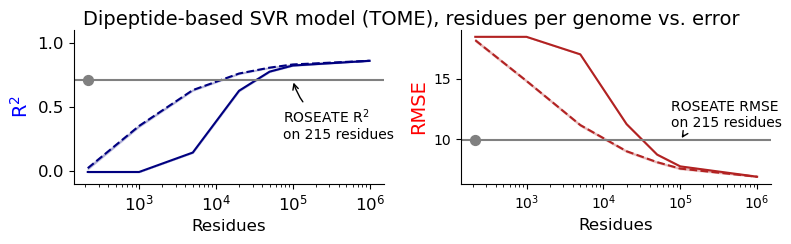

In [153]:

# target_width_px = 2500
# dpi = 400  # 300 DPI is standard for print/publication
# width_in = target_width_px / dpi  # 8.333... inches
# height_in = width_in * (2 / 4)    # 6.25 inches (yields 1875 px height)
# print(width_in, height_in)
fig = plt.figure(figsize=(9, 2))

ax = fig.add_subplot(1,2,1)

sns.lineplot(ax=ax, data=df.query("design == 'full'"), x='residues', y='r2', color='navy', linestyle='-')
sns.lineplot(ax=ax, data=df.query("design == 'matched'"), x='residues', y='r2', color='navy', linestyle='--')
# lgd = ax.legend(labels=['All residues', 'N = X residues'], loc='center left', bbox_to_anchor=(1.2, 0.5), title="Model training")
ax.set_ylabel('R$^{2}$', fontsize=14, color='blue')
ax.set_xlabel('Residues', fontsize=12)
plt.tick_params(top=False, labeltop=False, labelsize=12, axis='both')
ax.set_xscale('log')
ax.set_ylim(-0.1, 1.1)
ax.axhline(0.71, color='gray', linestyle='-')
ax.annotate('ROSEATE R$^{2}$\non 215 residues', (100000, 0.71), (75000, 0.5), va='top', 
            arrowprops=dict(
                arrowstyle="->",
                connectionstyle="arc3,rad=-0.3",  # Negative bends clockwise, positive counter-clockwise
                color="k",
                lw=1
            ))
ax.scatter((215), (0.71), color='gray', s=50, zorder=2)


ax = fig.add_subplot(1,2,2)
sns.lineplot(ax=ax, data=df.query("design == 'full'"), x='residues', y='rmse', color='firebrick', linestyle='-')
sns.lineplot(ax=ax, data=df.query("design == 'matched'"), x='residues', y='rmse', color='firebrick', linestyle='--')# hue='design')
ax.set_ylabel('RMSE', fontsize=14, color='red')
ax.set_xlabel('Residues', fontsize=12)
ax.axhline(9.9, color='gray', linestyle='-')
ax.set_xscale('log')
ax.annotate('ROSEATE RMSE\non 215 residues', (100000, 9.9), (75000, 12), ha='left', va='center',
             arrowprops=dict(
                arrowstyle="->",
                connectionstyle="arc3,rad=0.3",  # Negative bends clockwise, positive counter-clockwise
                color="k",
                lw=1
            ))
ax.scatter((215), (9.9), color='gray', s=50, zorder=2)
sns.despine()
fig.subplots_adjust(wspace=(0.25))
fig.suptitle('Dipeptide-based SVR model (TOME), residues per genome vs. error', fontsize=14)
plt.savefig('./../data/figures/finalized_figures/TOME_retraining.svg')

## Redoing and pipelining input MSA

The canonical number of ADKs with a good structure in this dataset is 8,532. The unaligned sequences for those ADKs are here: `data/20240122_all_adks_filtered.faa` (File A). File A is a subset of File B (`/data/20240122_all_adks.faa`), constructed by concatenating each best-hit adk per genome: `cat adks/*.faa > /data/20240122_all_adks.faa`. Sequences from File B were then folded with ColabFold, and filtered using `notebooks/02_filtering.ipynb` to make File C (`data/metric_tables/20240327_metrics_df_filtered.tsv.gz`).  
  
`File A = File B - File C.`
  
File A is the input to the MSA pipeline.

### Notes on MSA pipeline

Command:
```bash
python scripts/build_backbone.py --sequences data/20240122_all_adks_filtered.faa --exclude data/predictive_models/supporting_data/corkrey_sequence_ids.txt --outgroup data/high_qual_alignments/protein-matching-TIGR01351.fasta --compare-to data/high_qual_alignments/backbone.filtered_only.afa --replicates 5 --threads 30 --out data/backbone_alignment --overwrite --verbose
```

In [157]:
# clean up headers in outgroup file
# records = [r for r in SeqIO.parse('./../data/high_qual_alignments/protein-matching-TIGR01351.fasta', format='fasta')]